# Football Managerial Decision Analytics — Chapter 06
## Managerial patterns, evidence cards and conclusions

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate the repository, import the shared package, load the workspace
import os, sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.5s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## I · Managerial patterns

**Research question.** What do the recorded decisions show about selection, formation and substitution habits,
and how much of it is certain?

**Scope note.** This describes **observable decisions**. It does not measure a manager's ability or intentions
and cannot separate the manager from the squad he has. Every other manager in the data has two matches,
all against the focus team.

Manager identity source: StatsBomb matches.json (managers field)


,0
manager,Xabi Alonso
team,Bayer Leverkusen
matches,34
sample_status,comparable sample
points_per_match,2.650
xg_diff_per_match,1.320
formations_used,3
most_used_formation,3-4-2-1
most_used_share_pct,73.500
formation_diversity_index,0.610


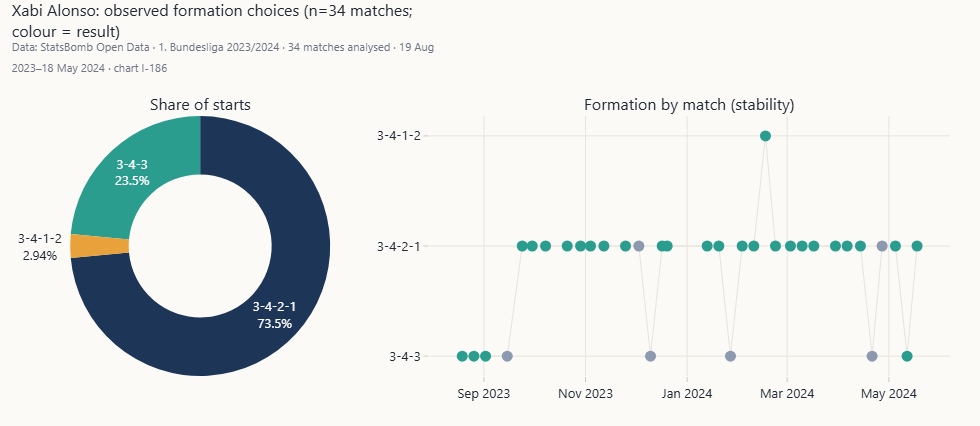

`I-186` Formation usage by manager · *Method:* Observed starting formations and results. · *Caveat:* Observable choices, not managerial ability.

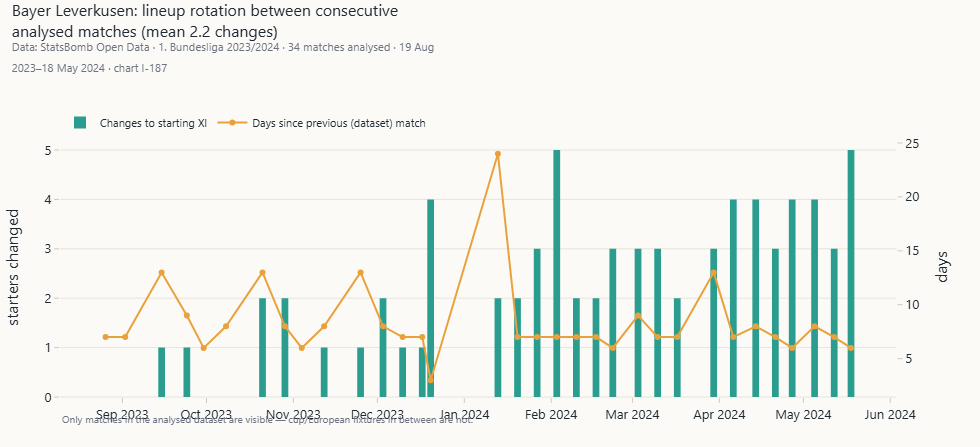

`I-187` Starting XI continuity and rotation trend · *Method:* Lineup changes between consecutive analysed matches. · *Caveat:* Cup and European matches between league games are not in the data.

**Interpretation.** Xabi Alonso (34 matches): 3 starting formations, 3-4-2-1 in 74% of matches; 2.21 changes to the XI between consecutive analysed matches; 4.18 substitutions per match with the first at a median of minute 64.

**Limitation.** Rotation is measured between league matches only; cup and European fixtures in between are missing.

In [2]:
prof = ws.manager_profiles()
mgr = ws.focus_manager()
print("Manager identity source:", B.manager_source)
display(prof[prof.manager == mgr].T)
show("I-186", ws)
show("I-187", ws)
r = prof[prof.manager == mgr].iloc[0]
interpret(f"{mgr} ({int(r.matches)} matches): {int(r.formations_used)} starting formations, {r.most_used_formation} in "
          f"{r.most_used_share_pct:.0f}% of matches; {r.mean_lineup_changes:.2f} changes to the XI between consecutive "
          f"analysed matches; {r.subs_per_match:.2f} substitutions per match with the first at a median of minute "
          f"{r.median_first_sub_minute:.0f}.")
limitation("Rotation is measured between league matches only; cup and European fixtures in between are missing.")

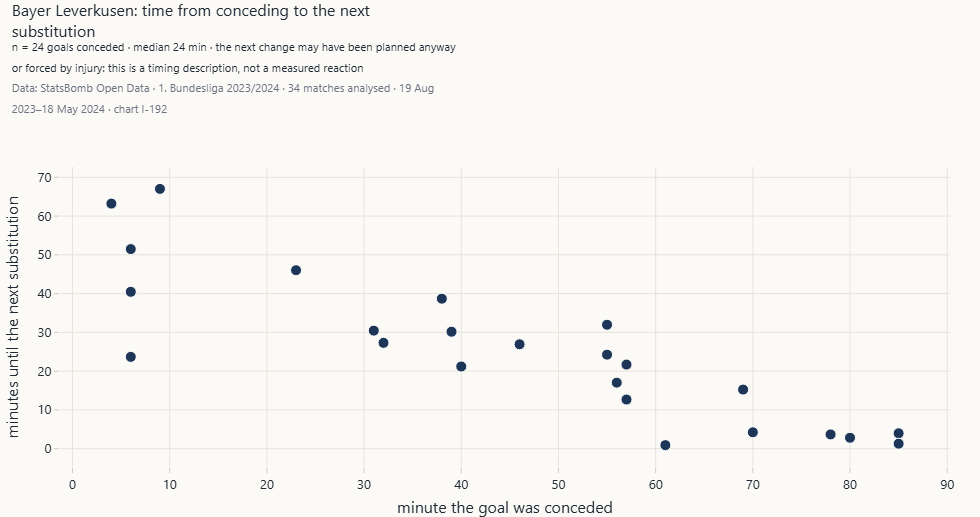

`I-192` Response timeline after conceding · *Method:* Minutes from a goal conceded to the next substitution. · *Caveat:* Timing description, not a measured reaction.

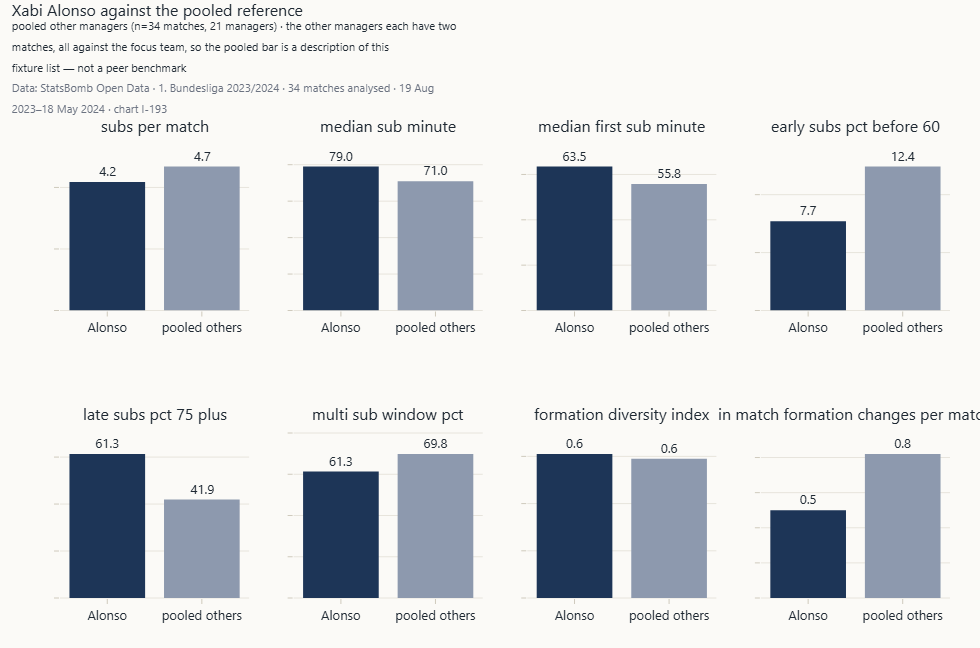

`I-193` Manager comparison small multiples · *Method:* Indicators next to the pooled value of all other managers. · *Caveat:* Other managers have two matches each, all against the focus team.

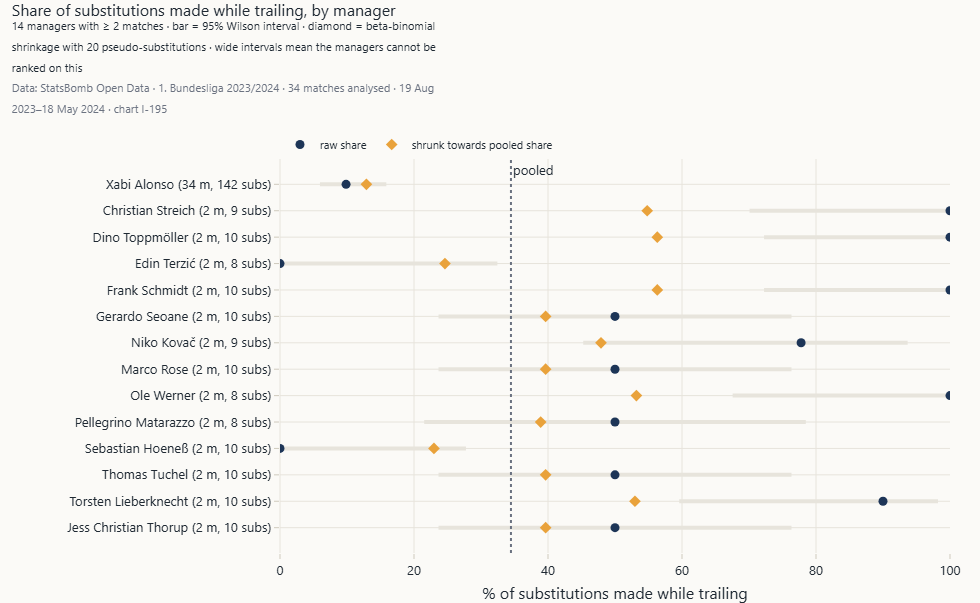

`I-195` Manager pattern uncertainty intervals · *Method:* Wilson intervals and beta-binomial shrinkage. · *Caveat:* Small samples cannot be ranked.

**Interpretation.** 21 of 22 managers have fewer than 10 matches. Their Wilson intervals span most of the scale and shrinkage pulls them to the pooled value — they cannot be ranked or compared with Xabi Alonso as peers.

In [3]:
show("I-192", ws)
show("I-193", ws)
show("I-195", ws)
small = prof[prof.matches < B.config.min_manager_matches]
interpret(f"{len(small)} of {len(prof)} managers have fewer than {B.config.min_manager_matches} matches. Their Wilson intervals "
          f"span most of the scale and shrinkage pulls them to the pooled value — they cannot be ranked or compared "
          f"with {mgr} as peers.")

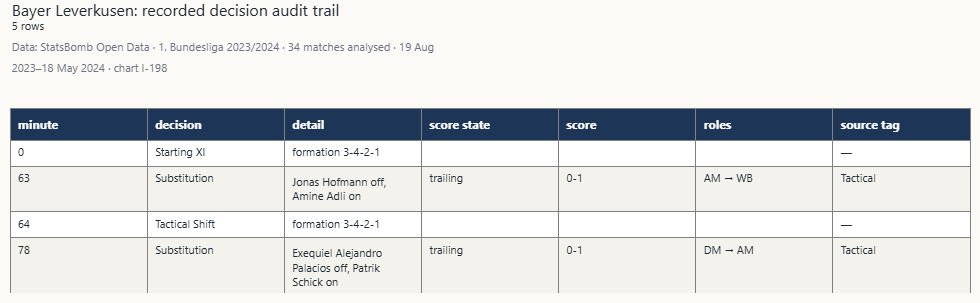

`I-198` Managerial decision audit trail · *Method:* Substitutions and formation records with context.

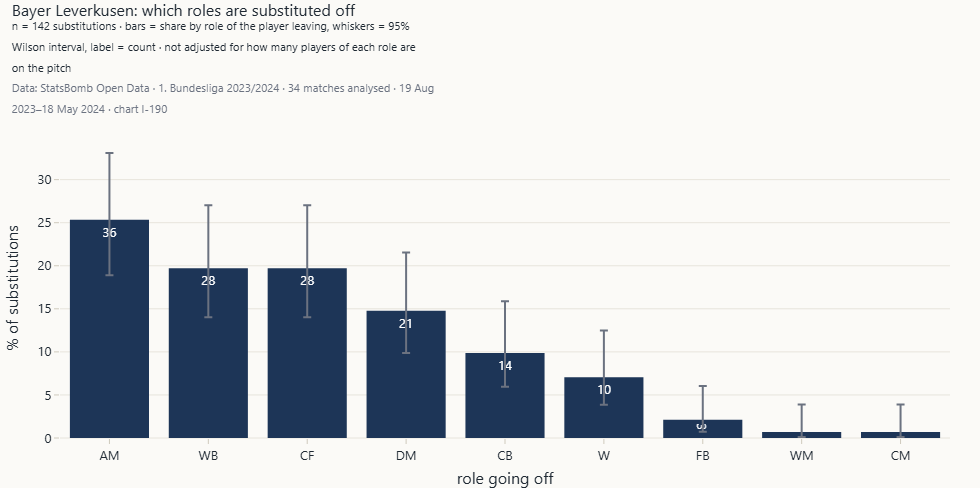

`I-190` Role-specific substitution tendency · *Method:* Share by role with Wilson intervals.

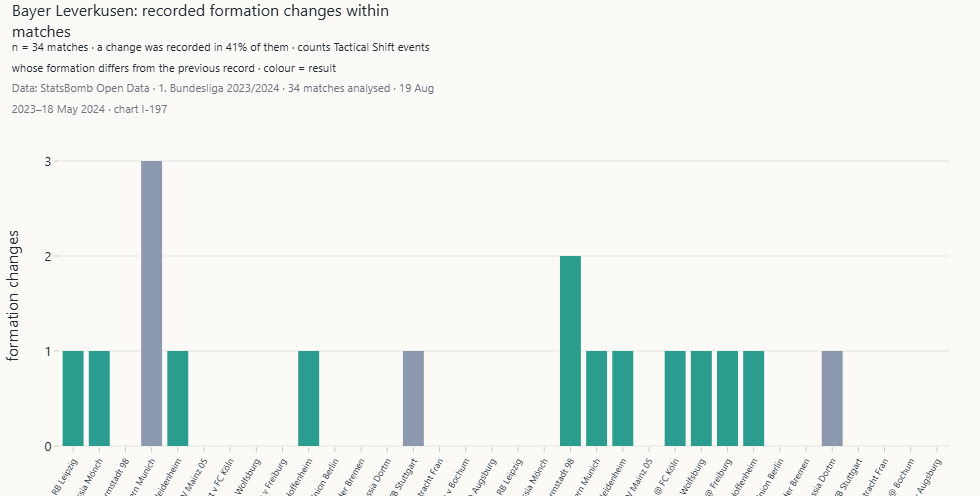

`I-197` Tactical change frequency · *Method:* Recorded Tactical Shift changes.

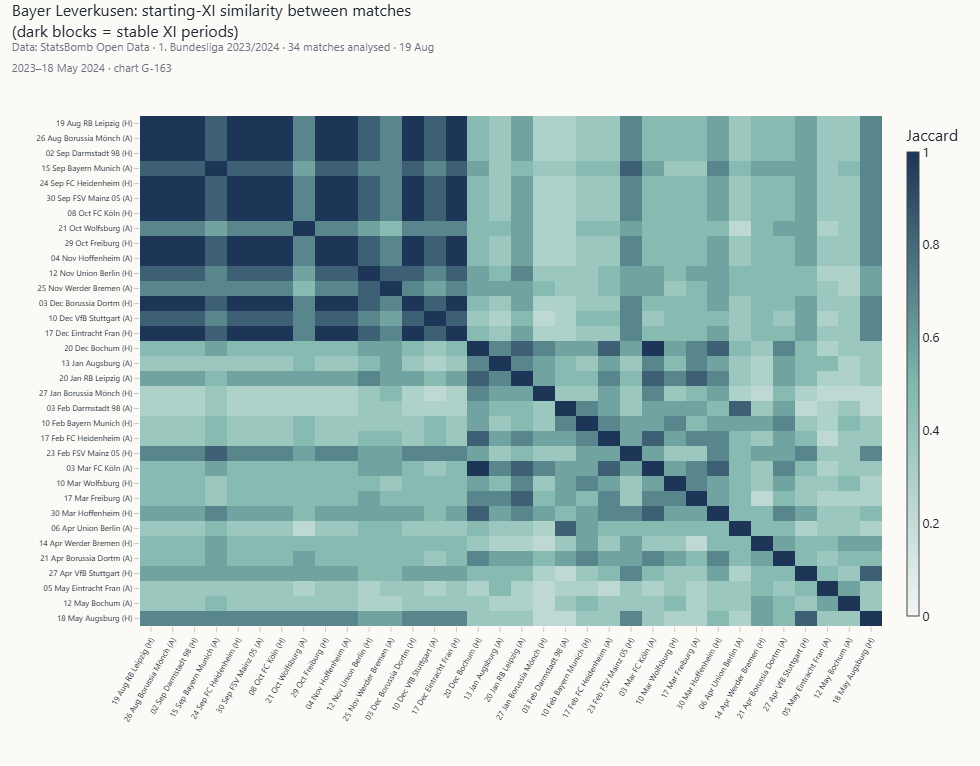

`G-163` Lineup similarity matrix · *Method:* Jaccard similarity of starting XIs.

In [4]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    mid = ws.default_match()
    show("I-198", ws, match_id=mid)
    show("I-190", ws)
    show("I-197", ws)
    show("G-163", ws)

## Evidence cards

Each card states the finding, the metric and value behind it, the scope, the supporting chart, why it may
matter and what the evidence cannot tell us. The text is assembled from computed values.

In [5]:
from src.reporting import insight_cards
cards = insight_cards.build_cards(ws)
display(Markdown(insight_cards.cards_markdown(cards)))

### 1. Results against chance quality

- **Finding.** Results ran ahead of shot-based expectation by 15.2 points.
- **Evidence.** 90 points vs 74.8 expected points; 89 goals from 72.7 xG (xG difference +1.32 per match).
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `L-262`
- **Managerial relevance.** Anchor performance reviews on chances created and conceded rather than on results alone.
- **What the evidence cannot tell us.** Expected points are a simulation from StatsBomb xG; they ignore game state and assume shots are independent.
- **Suggested next investigation.** Recompute over further seasons to see how much of the gap persists.

### 2. Concentration of chance creation

- **Finding.** Three players account for 40% of the squad's xG + xA.
- **Evidence.** Top three: Victor Boniface, Florian Wirtz, Álex Grimaldo; Gini coefficient of xG + xA across 22 contributors = 0.52.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `B-029`
- **Managerial relevance.** Cover and minutes management for the main creators matter more than for other roles.
- **What the evidence cannot tell us.** xA credits the passer of a shot assist only; off-ball contribution is not in event data.
- **Suggested next investigation.** Check how output changes in matches the top creators did not start.

### 3. Structure of the passing game

- **Finding.** Granit Xhaka is both the main hub and the main bridge of the pass network.
- **Evidence.** Mean PageRank 0.140 (Granit Xhaka); mean betweenness 0.211 (Granit Xhaka); averaged over 32 match networks.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `F-139`
- **Managerial relevance.** A build-up plan that depends on one link is exposed when he is pressed or unavailable.
- **What the evidence cannot tell us.** Networks use completed passes before the first substitution; centrality describes the recorded graph, not player quality.
- **Suggested next investigation.** Compare the network in matches where the hub was marked or absent.

### 4. Selection continuity

- **Finding.** A stable core with rotation at the margins: 7 players started at least three quarters of the matches.
- **Evidence.** Mean 2.2 starting-XI changes between consecutive analysed matches (median 2); 22 players started at least once.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `D-106`
- **Managerial relevance.** Decision support adds most in the two or three slots that actually rotate.
- **What the evidence cannot tell us.** Cup and European fixtures between league matches are not in the data, so rotation across all competitions is understated.
- **Suggested next investigation.** Add the other competitions' lineups to measure true rotation.

### 5. Substitution timing and score state

- **Finding.** Changes are made late and mostly from in front: median minute 79, 79% while leading.
- **Evidence.** 142 substitutions, 4.18 per match; 77% like-for-like by role.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `H-171`
- **Managerial relevance.** Pre-planned, role-compatible replacement pairs fit the observed pattern.
- **What the evidence cannot tell us.** Score state is driven by team strength: a team that usually leads makes most changes while leading whatever its intent.
- **Suggested next investigation.** Compare with matches of similar score state from other teams once more data are loaded.

### 6. Home and away performance

- **Finding.** A home edge in xG difference is suggestive but not established in this sample.
- **Evidence.** Home minus away xG difference +0.56 (95% CI -0.18 to +1.23); Cliff's δ 0.34 (medium); Mann–Whitney p = 0.098; n = 17 vs 17.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `J-211`
- **Managerial relevance.** Not strong enough to justify a different game model by venue.
- **What the evidence cannot tell us.** 17 matches per venue; opponents differ between the home and away sets.
- **Suggested next investigation.** Re-test with additional seasons.

### 7. What moves with goal difference

- **Finding.** 0 of 11 match variables remain associated with goal difference after false-discovery control; the strongest is xg against.
- **Evidence.** Spearman ρ = -0.43 (95% CI -0.72 to -0.05), q = 0.093; n = 34 matches.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `J-202`
- **Managerial relevance.** Chance quality for and against is the most informative match-level lens available here.
- **What the evidence cannot tell us.** One team-season: low power, and an association is not a causal effect.
- **Suggested next investigation.** Pool several seasons to raise power before drawing tactical conclusions.

### 8. Player profiles form a continuum

- **Finding.** Statistical profiles do not separate into distinct player types.
- **Evidence.** Best silhouette 0.32 at k = 2; the mixture-model BIC prefers k = 9; DBSCAN finds 1 dense group(s) with 3 outlying players; n = 70.
- **Scope.** 70 outfield players above the minutes threshold in the dataset
- **Supporting chart.** `K-240`
- **Managerial relevance.** Use role-specific metric profiles for squad planning rather than cluster labels.
- **What the evidence cannot tell us.** Opponent players are observed only in their matches against the focus team.
- **Suggested next investigation.** Repeat on full-league data, where every team has a full season of evidence.

### 9. How predictable is selection

- **Finding.** Past selection explains most starts; models add little over the simple rule.
- **Evidence.** Time-ordered cross-validation F1: Logistic regression 0.811 vs 0.775 for 'started the previous match'; hold-out ROC-AUC 0.775; 660 rows from 33 matches.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `K-221`
- **Managerial relevance.** Selection follows continuity; rotation decisions hinge on information the data lack.
- **What the evidence cannot tell us.** No fitness, injury, training or opponent-specific information exists in the source.
- **Suggested next investigation.** Add availability data before attempting to model rotation.


## J · Answers to the research questions and hypotheses

In [6]:
from src.analytics import descriptive as desc
from src.reporting.report_builder import results_snapshot
snap = results_snapshot(ws)
corr = ws.correlations().set_index("variable")
xg_side = corr.loc[["xg", "xg_against"], "spearman_rho"].abs().max()
answers = pd.DataFrame([
    ("H1 chance quality vs possession", f"|ρ| up to {xg_side:.2f} for xG for/against vs {abs(corr.loc['possession_proxy_pct', 'spearman_rho']):.2f} for possession proxy; "
     f"{snap['corr_significant_after_fdr']} of {len(corr)} variables significant after FDR", "direction supported; significance undecided at n = 34"),
    ("H2 results vs expectation", f"{snap['points']:.0f} points vs {snap['xpts']} expected points", "supported (model-based reference)"),
    ("H3 concentration of chance creation", f"top three = {snap['top3_chance_share']:.0%} of xG + xA", "supported"),
    ("H4 hub players", f"highest PageRank: {snap['hub_pagerank']}; highest betweenness: {snap['hub_betweenness']}", "supported (descriptive)"),
    ("H5 selection follows past selection", f"CV F1 {snap['cv_f1'][snap['best_model']]:.3f} vs {snap['cv_f1']['Baseline: started previous match']:.3f} baseline"
     if snap.get("model_fitted") else "model gate not met", "supported: small gain over the rule" if snap.get("model_fitted") else "not testable"),
    ("H6 substitution timing by score state", f"shortlist top-3 contains the actual substitute in {snap['sub_top3_share']:.0%} of cases", "descriptive only; confounded by team strength"),
], columns=["hypothesis", "evidence from this run", "verdict"])
display(answers)

,hypothesis,evidence from this run,verdict
0,H1 chance quality vs possession,|ρ| up to 0.43 for xG for/against vs 0.12 for ...,direction supported; significance undecided at...
1,H2 results vs expectation,90 points vs 74.8 expected points,supported (model-based reference)
2,H3 concentration of chance creation,top three = 40% of xG + xA,supported
3,H4 hub players,highest PageRank: Granit Xhaka; highest betwee...,supported (descriptive)
4,H5 selection follows past selection,CV F1 0.811 vs 0.775 baseline,supported: small gain over the rule
5,H6 substitution timing by score state,shortlist top-3 contains the actual substitute...,descriptive only; confounded by team strength


## Conclusions, limitations and next steps

**What the evidence supports.** The focus team's results rest on a large and consistent advantage in chance
volume; the points total ran ahead of shot-based expectation; chance creation and build-up are concentrated in
a few players; selection is dominated by a stable core; substitutions are late and mostly made from in front.

**What it does not support.** Any causal claim; any statement about the league or other teams' seasons; any
ranking of managers; any conclusion about fitness, injuries or fatigue.

**Limitations.** One team-season of league matches; opponents seen twice; no injury, fitness, tracking,
age or market data; xG, expected points and Expected Threat are model outputs; heuristic scores are valid only
under their stated weights.

**Next steps.** (1) Add several complete league seasons for benchmarks independent of one club. (2) Add the
other competitions the team played to measure real rotation. (3) Obtain availability data from an authorised
source before modelling rotation. (4) Use tracking or 360 data for off-ball questions. (5) Re-test the venue and
correlation findings with more matches.

In [7]:
# Machine-readable results of this run (the same numbers the reports are built from)
import json
print(json.dumps({k: v for k, v in snap.items() if k != "chart_status"}, indent=1, default=str, ensure_ascii=False))
display(timings().sort_values("seconds", ascending=False).head(10))

{
 "generated_utc": "2026-11-11 11:37 UTC",
 "focus_team": "Bayer Leverkusen",
 "synthetic": false,
 "matches": 34,
 "events": 137765,
 "players_in_squads": 460,
 "teams": 18,
 "raw_files": 70,
 "raw_mb": 120.05,
 "quality_checks": "16/16",
 "wins": 28,
 "draws": 6,
 "losses": 0,
 "points": 90.0,
 "xpts": 74.8,
 "goals_for": 89,
 "goals_against": 24,
 "xg_for": 72.7,
 "xg_against": 27.8,
 "top3_chance_share": 0.401,
 "hub_pagerank": "Granit Xhaka",
 "hub_betweenness": "Granit Xhaka",
 "corr_significant_after_fdr": 0,
 "corr_top": {
  "variable": "xg_against",
  "rho": -0.428,
  "ci": [
   -0.722,
   -0.054
  ],
  "q": 0.093,
  "n": 34
 },
 "venue": {
  "delta": 0.336,
  "p": 0.098,
  "mean_diff": 0.56
 },
 "xt": {
  "grid": "16x12",
  "moves": 71583,
  "shots": 916,
  "iterations": 79,
  "converged": true,
  "max_value": 0.293
 },
 "pca": {
  "pc1": 0.346,
  "pc2": 0.168,
  "components_for_80pct": 6,
  "players": 70
 },
 "clustering": {
  "k_best": 2,
  "silhouette": 0.318,
  "k_bic": 

,step,seconds
0,load workspace,2.530
1,chart I-186,2.040
2,chart I-187,1.960
3,chart I-192,1.960
4,chart I-193,1.950
9,chart G-163,1.950
6,chart I-198,1.920
5,chart I-195,1.910
8,chart I-197,1.900
7,chart I-190,1.880
